## 신경망의 학습과 평가


In [12]:
from copy import deepcopy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
torch.manual_seed(SEED)  # 모델 초기화 등에 사용하는 난수 시드


### 손글씨 숫자 분류

손글씨 이미지의 픽셀 64개를 입력으로 받아 숫자 0~9를 분류하는 MLP를 학습한다.


In [13]:
digits = load_digits()
X, y = digits.data, digits.target  # 입력 (1797, 64), 정답 (1797,)
print("입력:", X.shape, "정답:", y.shape)


입력: (1797, 64) 정답: (1797,)


### 학습·검증·테스트 나누기

픽셀 값을 최댓값 16으로 나누어 0~1 범위로 바꾼다. 학습·검증·테스트 데이터에 같은 변환을 적용한다.


In [14]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)  # stratify: 클래스 비율 유지
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, stratify=y_train_val, random_state=SEED)

train_inputs = torch.tensor(X_train / 16.0, dtype=torch.float32)  # 픽셀을 0~1 범위의 실수 텐서로 변환
val_inputs = torch.tensor(X_val / 16.0, dtype=torch.float32)
test_inputs = torch.tensor(X_test / 16.0, dtype=torch.float32)
train_labels = torch.tensor(y_train, dtype=torch.long)  # 분류 정답은 정수 클래스 번호
val_labels = torch.tensor(y_val, dtype=torch.long)
test_labels = torch.tensor(y_test, dtype=torch.long)
print("학습·검증·테스트:", len(train_labels), len(val_labels), len(test_labels))


학습·검증·테스트: 1077 360 360


### 이미지를 배치로 묶기

배치는 한 번에 처리하는 데이터 묶음이다. 이미지를 일정한 개수씩 묶으면 한 번에 필요한 메모리 양을 조절하고, 여러 이미지를 함께 계산할 수 있다. 학습할 때는 배치에 담긴 이미지들의 평균 손실을 구해 가중치를 한 번 갱신한다.

학습 이미지를 32장씩 묶으면 입력 모양은 `(32, 64)`가 된다. 32는 한 번에 처리하는 이미지 수이고, 64는 이미지 한 장의 픽셀 수다.

`TensorDataset`은 같은 위치의 입력과 정답을 묶는다. `DataLoader`는 이 데이터에서 배치를 꺼내며 학습할 때 순서를 섞을 수 있다.


In [15]:
train_dataset = TensorDataset(train_inputs, train_labels)  # 같은 위치의 이미지와 정답을 한 쌍으로 묶는다.
train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True,  # 이미지를 32장씩 묶고, 매 순회마다 순서를 섞는다.
    generator=torch.Generator().manual_seed(SEED))  # 배치 순서 재현용 난수 생성기
xb, yb = next(iter(train_loader))  # 첫 배치: 이미지 xb (32, 64), 정답 yb (32,)
print("배치 수:", len(train_loader), "입력:", xb.shape, "정답:", yb.shape)


배치 수: 34 입력: torch.Size([32, 64]) 정답: torch.Size([32])


### 모델과 손실

MLP는 입력 64개를 은닉 값 32개로 바꾸고, ReLU를 거쳐 숫자별 로짓 10개를 출력한다.
`nn.Sequential`은 층을 순서대로 연결하고, `nn.Linear`는 가중합과 편향을 계산한다.

손실은 예측과 정답의 차이를 학습에 사용할 숫자로 나타낸다. 여러 클래스 중 하나를 예측하는 분류 문제에는 교차 엔트로피 손실 함수를 사용할 수 있다. 정답 클래스에 부여한 확률이 낮을수록 손실값이 커진다.
`nn.CrossEntropyLoss`는 로짓과 정수 정답을 받아 평균 손실을 계산한다. 내부에서 확률에 해당하는 계산을 수행하므로 모델의 마지막 층은 로짓을 출력한다.


In [16]:
def make_model(hidden_size=32):  # hidden_size: 은닉층 뉴런 수
    return nn.Sequential(
        nn.Linear(64, hidden_size), 
        nn.ReLU(), 
        nn.Linear(hidden_size, 10)
        )

model = make_model()
criterion = nn.CrossEntropyLoss()  # 로짓과 정수 정답을 받아 배치의 평균 손실을 계산한다.
logits = model(xb)  # (32, 10)
loss = criterion(logits, yb)  # 정답 (32,), 반환값은 평균 손실 하나
print("손실값:", loss.item())  # item(): 텐서에서 숫자 하나를 꺼낸다.


손실값: 2.2925174236297607


### 학습 전 결과 확인

정확도는 전체 이미지 중 맞힌 비율이다. 손실과 정확도를 함께 보면 정답에 부여한 확률과 실제로 맞힌 비율을 확인할 수 있다.


In [17]:
def evaluate(model, inputs, labels):
    model.eval()  # 평가 모드
    with torch.no_grad():  # 현재 가중치로 예측만 계산한다.
        scores = model(inputs)  # 이미지별 클래스 점수, (이미지 수, 10)
        loss_value = criterion(scores, labels).item()
        # 클래스 축(dim=1)에서 가장 큰 점수의 위치를 고르고, 정답 여부를 1·0으로 바꿔 평균한다.
        accuracy = (scores.argmax(dim=1) == labels).float().mean().item()
    return loss_value, accuracy  # 평균 손실과 정확도를 반환한다.

initial_val_loss, initial_val_accuracy = evaluate(model, val_inputs, val_labels)
print("학습 전 검증 손실·정확도:", initial_val_loss, initial_val_accuracy)


학습 전 검증 손실·정확도: 2.294483184814453 0.08055555820465088


### 손실로 가중치 바꾸기

학습은 손실이 줄어드는 방향으로 가중치와 편향을 조금씩 바꾸는 과정이다. 이때 각 값을 조금 바꾸면 손실이 어느 방향으로 얼마나 변하는지를 나타내는 것이 기울기다.

역전파는 각 가중치와 편향의 기울기를 구하는 과정이다. 손실에서 시작해 출력층부터 앞쪽 층으로 계산을 거슬러 올라가며, 뒤에서 구한 기울기를 이용해 앞쪽의 기울기를 계산한다.

옵티마이저는 구한 기울기를 이용해 가중치와 편향을 실제로 갱신한다. 학습률은 한 번에 값을 바꾸는 크기를 조절하는 기준이다. 여기서는 파라미터마다 갱신 크기를 조절하는 Adam을 사용한다.

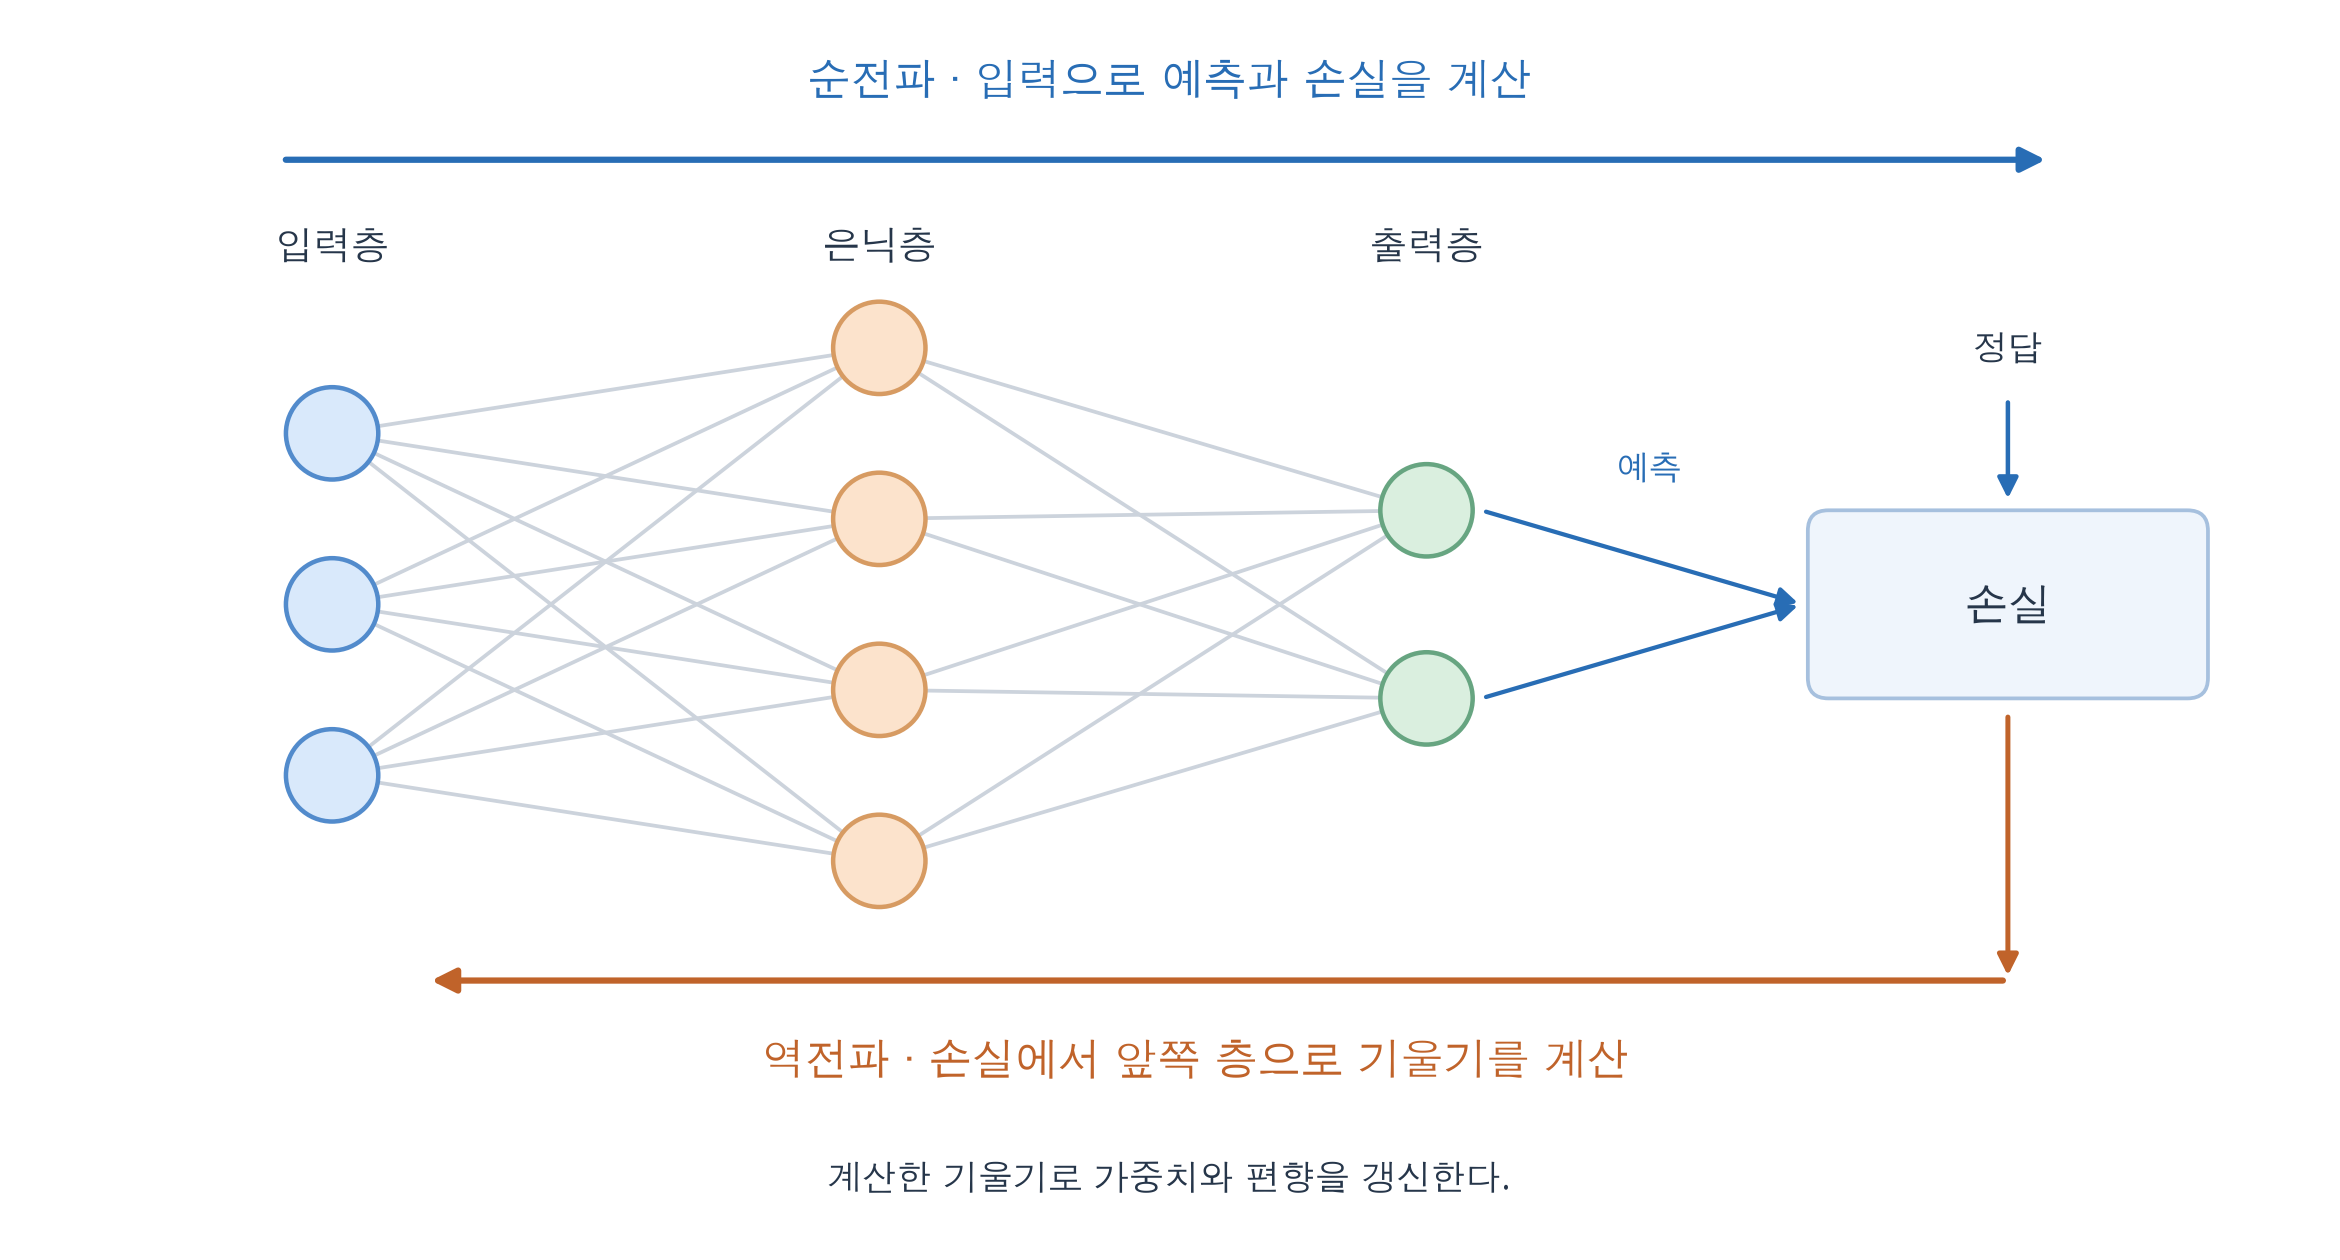

| 호출 | 역할 |
| --- | --- |
| `zero_grad()` | 이전 계산에서 쌓인 기울기를 지운다 |
| `backward()` | 현재 손실에 대한 기울기를 계산한다 |
| `step()` | 계산된 기울기로 파라미터를 갱신한다 |

같은 배치에서 갱신 전후의 손실을 비교한다. 실제 손실 변화는 데이터와 학습률, 갱신 방식에 따라 달라진다.


In [18]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)  # parameters(): 가중치·편향, lr: 학습률
model.train()  # 학습 모드
logits = model(xb)
loss = criterion(logits, yb)
optimizer.zero_grad()  # 이전 기울기를 지운다. 가중치와 편향은 유지된다.
loss.backward()  # 역전파로 현재 손실에 대한 각 파라미터의 기울기를 구한다.
optimizer.step()  # 구한 기울기로 가중치와 편향을 갱신한다.

with torch.no_grad():
    updated_loss = criterion(model(xb), yb).item()  # 갱신된 가중치로 같은 배치의 손실을 다시 계산한다.
print("같은 배치의 갱신 전·후 손실:", loss.item(), updated_loss)


같은 배치의 갱신 전·후 손실: 2.2925174236297607 2.2824604511260986


## 반복 학습과 결과 해석

모든 학습 배치를 한 번씩 사용해 전체 학습 데이터를 한 번 학습하는 단위를 에포크라고 한다. 20에포크는 이 과정을 20번 반복한다는 뜻이다.

한 배치로 갱신한 모델을 이어서 학습한다. 각 에포크에서 모든 학습 배치로 가중치를 갱신한 뒤 학습·검증 손실과 정확도를 기록한다.
학습 곡선은 각 에포크가 끝난 모델로 계산하므로, 같은 시점의 학습 결과와 검증 결과를 비교할 수 있다.

매 에포크의 검증 손실을 비교해 가장 작았던 시점의 가중치와 편향을 저장한다. 학습이 끝나면 저장한 값으로 되돌려 최종 모델로 사용한다.


In [19]:
def fit(model, optimizer, loader, epochs=20):  # epochs: 전체 학습 데이터를 반복해서 사용할 횟수
    history = []
    best_loss = float("inf")  # 첫 검증 손실부터 비교할 수 있도록 무한대로 시작한다.
    best_state = deepcopy(model.state_dict())  # 파라미터를 이후 갱신의 영향을 받지 않는 복사본으로 보관한다.
    for epoch in range(epochs):
        model.train()
        for inputs, labels in loader:  # 한 배치씩 가중치를 갱신하며 모든 학습 데이터를 사용한다.
            loss = criterion(model(inputs), labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        # 한 에포크가 끝난 시점의 모델로 학습·검증 결과를 기록한다.
        train_loss, train_accuracy = evaluate(model, train_inputs, train_labels)
        val_loss, val_accuracy = evaluate(model, val_inputs, val_labels)
        history.append({"epoch": epoch + 1, "train_loss": train_loss, "val_loss": val_loss,
                        "train_accuracy": train_accuracy, "val_accuracy": val_accuracy})
        if val_loss < best_loss:  # 검증 손실이 가장 작았던 시점의 파라미터를 보관한다.
            best_loss = val_loss
            best_state = deepcopy(model.state_dict())
    model.load_state_dict(best_state)  # 선택한 시점의 가중치와 편향을 모델에 복원한다.
    return pd.DataFrame(history)  # 에포크별 손실·정확도를 표로 반환한다.

history = fit(model, optimizer, train_loader)
display(history.iloc[:])  # 첫 에포크와 마지막 에포크의 기록


,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,1,2.171412,2.166636,0.395543,0.413889
1,2,1.984591,1.981732,0.709378,0.691667
2,3,1.737797,1.738957,0.812442,0.808333
3,4,1.444588,1.450884,0.844940,0.841667
4,5,1.161407,1.175394,0.857939,0.861111
5,6,0.934065,0.958377,0.874652,0.886111
6,7,0.770247,0.797797,0.883937,0.877778
7,8,0.652522,0.688329,0.893222,0.888889
8,9,0.565842,0.602446,0.896936,0.897222
9,10,0.501428,0.538365,0.905292,0.908333


### 학습 곡선 읽기

가로축은 에포크, 세로축은 손실 또는 정확도다. 손실은 작을수록, 정확도는 클수록 좋다.
학습 손실이 줄면서 검증 손실도 줄면 새로운 이미지에서도 예측이 개선되는 흐름이다.
학습 손실이 줄어드는 동안 검증 손실이 커지면 학습 사례에 과하게 맞춰지는 과적합을 의심할 수 있다.
이때는 학습 횟수나 모델 크기를 줄이는 등의 조건을 검증 데이터로 비교한다.


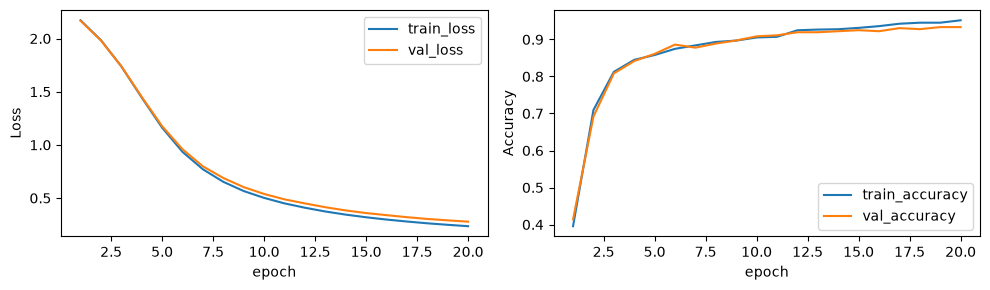

,stage,val_loss,val_accuracy
0,before,2.294483,0.080556
1,after,0.277948,0.933333


선택한 에포크: 20


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
history.plot(x="epoch", y=["train_loss", "val_loss"], ax=axes[0], ylabel="Loss")
history.plot(x="epoch", y=["train_accuracy", "val_accuracy"], ax=axes[1], ylabel="Accuracy")
plt.tight_layout()
plt.show()

final_val_loss, final_val_accuracy = evaluate(model, val_inputs, val_labels)
display(pd.DataFrame({"stage": ["before", "after"],
                      "val_loss": [initial_val_loss, final_val_loss],
                      "val_accuracy": [initial_val_accuracy, final_val_accuracy]}))
# idxmin(): 검증 손실이 가장 작은 행의 인덱스
print("선택한 에포크:", int(history.loc[history.val_loss.idxmin(), "epoch"]))


### 잘못 예측한 이미지 확인

검증 이미지에서 잘못 예측한 사례의 정답과 예측을 비교한다. 획의 모양이나 굵기에서 혼동의 단서를 찾아본다.
표시한 일부 사례와 전체 이미지의 오류 경향을 구분해서 해석한다.


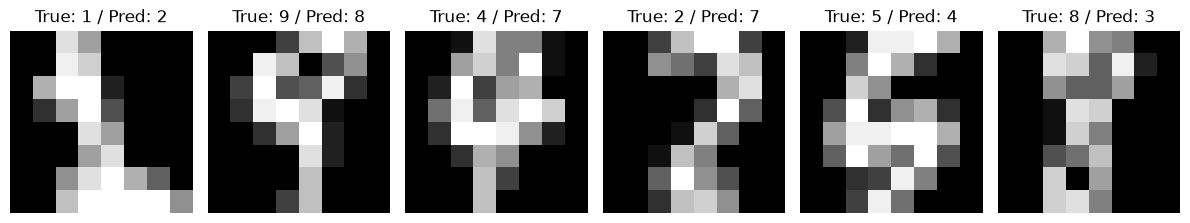

In [21]:
model.eval()
with torch.no_grad():
    val_predictions = model(val_inputs).argmax(dim=1).numpy()
error_positions = np.flatnonzero(y_val != val_predictions)[:6]  # flatnonzero(): 조건이 참인 위치를 찾아 최대 6개 선택
if len(error_positions):
    fig, axes = plt.subplots(1, len(error_positions), figsize=(2 * len(error_positions), 2.5), squeeze=False)  # 이미지가 한 장이어도 axes를 2차원으로 유지
    for ax, position in zip(axes.flat, error_positions):
        ax.imshow(X_val[position].reshape(8, 8), cmap="gray", vmin=0, vmax=16)
        ax.set_title(f"True: {y_val[position]} / Pred: {val_predictions[position]}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("이 검증 분할에서는 오분류가 없습니다.")


### 테스트 정확도 확인

검증 손실을 기준으로 선택한 모델을 테스트 데이터 전체에서 평가한다. 테스트 정확도는 학습과 모델 선택에 사용하지 않은 이미지에서 정답을 맞힌 비율이다.


In [22]:
_, test_accuracy = evaluate(model, test_inputs, test_labels)  # 반환값 중 정확도를 사용한다.
print(f"테스트 정확도: {test_accuracy:.2%}")


테스트 정확도: 92.50%


### 학습한 모델로 이미지 한 장 예측하기

테스트 이미지 한 장을 학습한 모델에 넣고, 예측한 숫자와 정답을 비교한다.


정답: 5 예측: 5


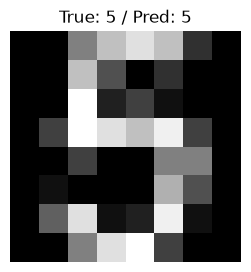

In [23]:
image_input = test_inputs[:1]  # 전처리된 이미지 한 장, (1, 64)
model.eval()
with torch.no_grad():
    scores = model(image_input)  # 숫자 0~9의 점수, (1, 10)
prediction = scores.argmax(dim=1).item()  # 가장 높은 점수를 받은 숫자
print("정답:", y_test[0], "예측:", prediction)

plt.figure(figsize=(3, 3))
plt.imshow(X_test[0].reshape(8, 8), cmap="gray", vmin=0, vmax=16)
plt.title(f"True: {y_test[0]} / Pred: {prediction}")
plt.axis("off")
plt.show()


## 연습문제: 학습 조건 바꾸기

모델의 구조와 학습 방식을 정하는 설정을 하이퍼파라미터라고 한다. 지금 코드에서 바꿀 수 있는 하이퍼파라미터가 무엇인지 생각해 보자.

그중 바꿔 보고 싶은 항목을 골라 값을 변경하고, 모델을 새로 학습해 보자. 검증 정확도와 학습 곡선을 비교하며 결과가 어떻게 달라지는지 살펴보자.
